## DS2023 Project 2

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact

### Load Data

In [2]:
#Loading in data
#Check for missing values is in looking_at_data_options.ipynb


living_cases_url = 'https://virginia.box.com/shared/static/hfkttdmmyd4dg3sh7qumusevxxduimyq.csv'
living_cases = pd.read_csv(living_cases_url)
new_cases_url = 'https://virginia.box.com/shared/static/zjmyugj5gh68e5kuw2a923w1r2t55l0s.csv'
new_cases = pd.read_csv(new_cases_url)
deaths_url = 'https://virginia.box.com/shared/static/cssyj0b90kbzjesyfjfd08ohrownn0uj.csv'
deaths = pd.read_csv(deaths_url)

# Combine the CSVs without error
# Solution provided by Prof. Alvarado

'''It turns out that each table had two different category names, corresponding to their unit of observation.
So, [Prof. Alvarado] just changed them, but the user should know what 'Age' and 'City' actually mean when viewing results.'''

key = ['Year', 'Category', 'Group']

df1 = living_cases.rename(columns={'Count': 'Count_Living'})
df1['Category'] = df1['Category'].replace({'Age at Year End (in years)':'Age', 'City of Current Residence':'City', 'County of Current Residence':'County'})
df1 = df1.set_index(key)

df2 = new_cases.rename(columns={'Count': 'Count_New'})
df2['Category'] = df2['Category'].replace({'Age at Diagnosis (in years)':'Age', 'City of Residence at Diagnosis':'City', 'County of Residence at Diagnosis':'County'})
df2 = df2.set_index(key)

df3 = deaths.rename(columns={'Count': 'Count_Deaths'})
df3['Category'] = df3['Category'].replace({'Age at Death (in years)':'Age', 'City of Residence at Death':'City', 'County of Residence at Death':'County'})
df3 = df3.set_index(key)

hiv_aids = df1.join(df2).join(df3)

hiv_aids.head()



Count_Living  Count_New  Count_Deaths
Year Category Group                                          
2010 Age      0 to 11            174       16.0             1
              12 to 14           112        3.0             0
              15 to 17           206       30.0             1
              18 to 19           345      131.0             1
              20 to 24          3001      780.0            15

In [3]:
#Population totals per Year/Category/Group, pre-computed from the 117 MB CA population file by build_pop_by_group.py
#(raw file: https://virginia.box.com/shared/static/k8m08mo65opxkqtzr4cy3btbyk8dkvmt.csv)
#Box share page: https://virginia.box.com/s/k8o4d1qaewdguykqaz0iau6fv9arxyjy (the /shared/static/ form below is the direct download)
pop_by_group_url = 'https://virginia.box.com/shared/static/k8o4d1qaewdguykqaz0iau6fv9arxyjy.csv'
pop_by_group = pd.read_csv(pop_by_group_url)

pop_by_group.head()

,Year,Category,Group,Population
0,2010,Age,0 to 11,6063163.0
1,2010,Age,12 to 14,1567210.0
2,2010,Age,15 to 17,1663032.0
3,2010,Age,18 to 19,1154752.0
4,2010,Age,20 to 24,2777593.0


In [4]:
#back to regular columns so the keys are available for plotting and grouping
hiv_aids = hiv_aids.reset_index()
hiv_aids.head()
hiv_aids.info()


<class 'pandas.DataFrame'>
RangeIndex: 1722 entries, 0 to 1721
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Year          1722 non-null   int64  
 1   Category      1722 non-null   str    
 2   Group         1722 non-null   str    
 3   Count_Living  1722 non-null   int64  
 4   Count_New     1721 non-null   float64
 5   Count_Deaths  1722 non-null   int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 80.8 KB


In [5]:
#  MERGING POPULATION DATA WITH HIV DATA
#how pop_by_group is built (county-only rows, relabeled races, age bins matching the HIV data, city rows from the lhj rows) is in build_pop_by_group.py

#left join so Current Gender and Transmission keep a null population rather than being dropped
hiv_aids = hiv_aids.merge(pop_by_group, on=['Year','Category','Group'], how='left')


#adding analytical columns to hiv_aids (rates per 100,000 people)
hiv_aids['Prevalence_per_100k'] = hiv_aids.Count_Living / hiv_aids.Population * 100000
hiv_aids['Death_Rate'] = hiv_aids.Count_Deaths / hiv_aids.Population * 100000
hiv_aids['Diagnosis_Rate'] = hiv_aids.Count_New / hiv_aids.Population * 100000

In [6]:
#"Transmission Category: ..." labels are the same risk groups split by gender, collapsing them into one category keeps the dropdown from having six near-identical options
#copying dataset to not interfere with group member's work!
linedf = hiv_aids.copy()
linedf['Category'] = linedf.Category.str.replace(r'^Transmission Category:.*', 'Transmission', regex=True)

#collapsing the narrow age bands into four
age_groups = {'20 to 24':'Under 35', '25 to 29':'Under 35', '30 to 34':'Under 35',
              '35 to 39':'35 to 49', '40 to 44':'35 to 49', '45 to 49':'35 to 49',
              '50 to 54':'50 to 64', '55 to 59':'50 to 64', '60 to 64':'50 to 64',
              '65 to 74':'65 and over', '>= 75':'65 and over'}
linedf['Group'] = linedf.Group.replace(age_groups)
age_order = ['Under 35', '35 to 49', '50 to 64', '65 and over']

#summing so each Year/Category/Group appears once after the collapsing
#min_count keeps Population null for transmission and gender instead of summing nulls to zero
linedf = linedf.groupby(['Year','Category','Group'], as_index=False).agg(
    Count_Living=('Count_Living','sum'), Count_New=('Count_New','sum'),
    Count_Deaths=('Count_Deaths','sum'), Population=('Population', lambda p: p.sum(min_count=1)))

#averaging a "group size" column using counts across years, then dropping the groups too small for a stable rate
linedf['Group_Size'] = linedf.groupby(['Category','Group']).Count_Living.transform('mean')
linedf = linedf[linedf.Group_Size >= 1000]

#rates recomputed after groupings, using both denominators: people living with HIV, and all Californians
linedf['Death_Rate'] = linedf.Count_Deaths / linedf.Count_Living * 1000
linedf['Deaths_per_100k'] = linedf.Count_Deaths / linedf.Population * 100_000
linedf['Prevalence_per_100k'] = linedf.Count_Living / linedf.Population * 100_000
linedf['Diagnosis_per_100k'] = linedf.Count_New / linedf.Population * 100_000

#each measure needs its rate column plus the two counts to rebuild it for the Total view
measures = {'Deaths per 1,000 living with HIV': ('Death_Rate','Count_Deaths','Count_Living',1000),
            'Deaths per 100,000 Californians': ('Deaths_per_100k','Count_Deaths','Population',100_000),
            'People living with HIV per 100,000 Californians': ('Prevalence_per_100k','Count_Living','Population',100_000),
            'New diagnoses per 100,000 Californians': ('Diagnosis_per_100k','Count_New','Population',100_000)}

@interact(category=['Total','Age','Race/Ethnicity','Sex at Birth','Transmission'],
          measure=list(measures))
def plot_rates(category, measure):
    rate_col, top, bottom, scale = measures[measure]

    if category == 'Total':
        #using one category to avoid double counting, since the same person appears in every category
        by_year = linedf[linedf.Category == 'Race/Ethnicity'].groupby('Year')[[top, bottom]].sum()
        rate_over_time = (by_year[top] / by_year[bottom] * scale).to_frame('Californians with HIV/AIDS')
    else:
        rate_over_time = linedf[linedf.Category == category].pivot(index='Year', columns='Group', values=rate_col)
        if category == 'Age':
            rate_over_time = rate_over_time[age_order]

    #there is no population count for transmission risk groups, so those combinations have no denominator
    if rate_over_time.isna().all().all():
        print(f'{measure} is not available for {category}, since the population file has no denominator for those groups.')
        return

    ax = rate_over_time.plot.line(figsize=(9,5))

    ax.set_ylim(0, None)
    ax.set_xlim(2010, 2023)
    ax.set_xlabel('Year')
    ax.set_ylabel(measure)
    ax.set_title(measure if category == 'Total' else f'{measure} by {category}')
    ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='category', options=('Total', 'Age', 'Race/Ethnicity', 'Sex at Birt…

Notes: 

Age is likely a large factor in this, and that is actually still valuable information directly related to HIV because comorbidity due to immunosuppression is what actually causes deaths. 

Multiple races is a very large category (over 6k), but issues of reclassifaction and how data is collected can make tracking for multiracial people very confusing. Should we drop the category?

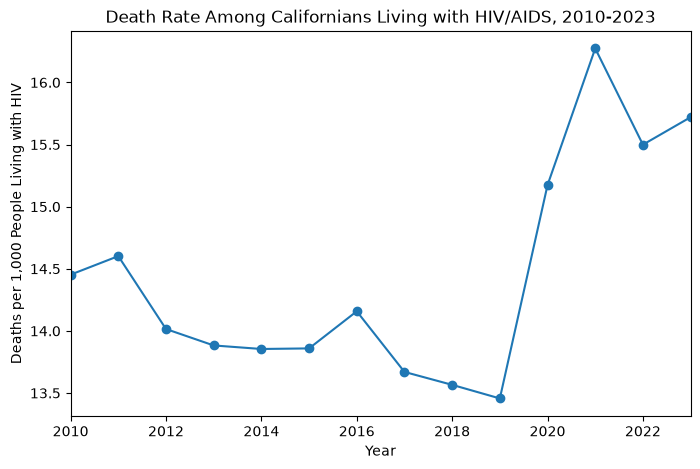

In [7]:
#computing death rate over time by year
by_year = hiv_aids[hiv_aids.Category == 'Race/Ethnicity'].groupby('Year')[['Count_Living','Count_Deaths']].sum() #using one category to avoid double counting, since the same person can be counted in multiple categories
death_rate_over_time = by_year.Count_Deaths / by_year.Count_Living * 1000

ax = death_rate_over_time.plot.line(marker='o', figsize=(8,5))
ax.set_xlabel('Year')
ax.set_xlim(2010, 2023)
ax.set_ylabel('Deaths per 1,000 People Living with HIV')
ax.set_title('Death Rate Among Californians Living with HIV/AIDS, 2010-2023')
plt.show()

#could maybe annotate the graph with a line of overall california death rate

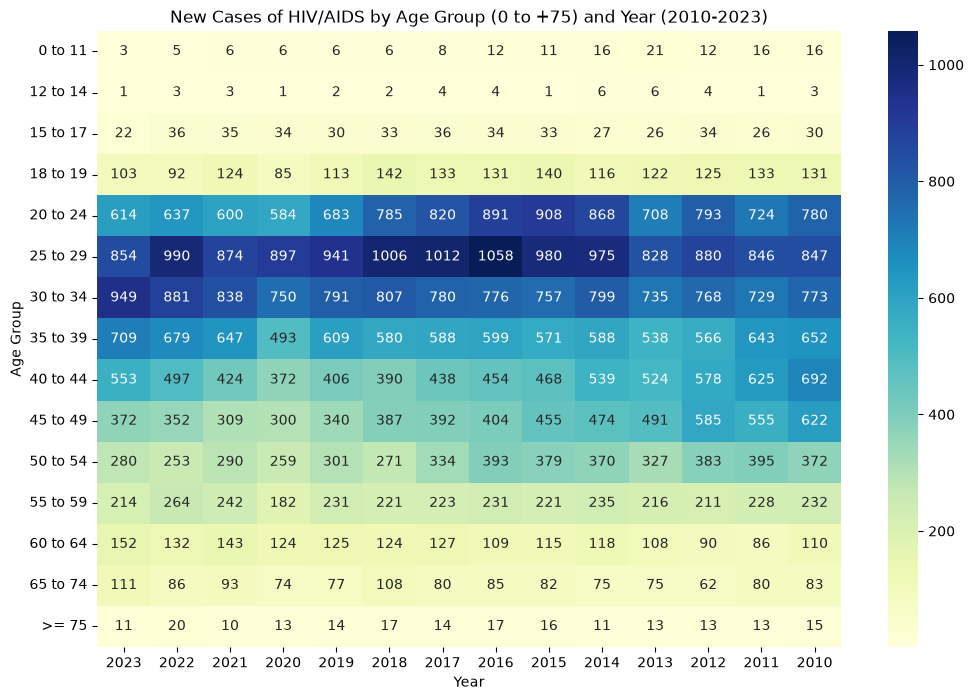

In [8]:
# heatmap of age and new case counts
age = hiv_aids[hiv_aids["Category"] == "Age"].pivot(
    index="Year", columns="Group", values="Count_New" # selected new cases for the heatmap, but could also do living or deaths
).sort_index(ascending=False).T # I'm not sure why it's not in descending order

plt.figure(figsize=(12, 8))
sns.heatmap(age, cmap="YlGnBu", annot=True, fmt="g") 
plt.xlabel("Year")
plt.xticks(rotation=0)
plt.ylabel("Age Group")
plt.yticks(rotation=0)
plt.title("New Cases of HIV/AIDS by Age Group (0 to +75) and Year (2010-2023)")
plt.show()

# could use plotly for an interactive heatmap